# Part 2 – Neural Network Control of the Robot

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     RepeatedStratifiedKFold, cross_val_score)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score, mean_squared_error)

action_names = ["south", "north", "east", "west", "pickup", "dropoff"]

## 1. Data

In [2]:
# load the dataset created in Part 1
full_dataset_df = pd.read_csv("taxi_dataset_404.csv", index_col="state")

print(full_dataset_df.shape)
print(full_dataset_df["best_action"].value_counts().sort_index())

(404, 5)
best_action
0    114
1    145
2     56
3     73
4     12
5      4
Name: count, dtype: int64


In [3]:
# dumping the finished states from the dataset
dataset_df = full_dataset_df.drop([0, 85, 410, 475])
print(dataset_df.shape)

(400, 5)


In [4]:
X = dataset_df[["taxi_row", "taxi_col", "pass_idx", "dest_idx"]]
y = dataset_df["best_action"]

print(X.shape)  
print(y.shape)   

(400, 4)
(400,)


### 1.1. Input encoding

In [5]:
# one-hot encode pass_idx and dest_idx
X_onehot = pd.get_dummies(X, columns=["pass_idx", "dest_idx"]).astype(int)

print(X_onehot.shape)
X_onehot.to_csv("taxi_dataset_one_hot_encode.csv")
X_onehot

(400, 11)


,taxi_row,taxi_col,pass_idx_0,pass_idx_1,pass_idx_2,pass_idx_3,pass_idx_4,dest_idx_0,dest_idx_1,dest_idx_2,dest_idx_3
state,,,,,,,,,,,
1,0,0,1,0,0,0,0,0,1,0,0
2,0,0,1,0,0,0,0,0,0,1,0
3,0,0,1,0,0,0,0,0,0,0,1
4,0,0,0,1,0,0,0,1,0,0,0
6,0,0,0,1,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
494,4,4,0,0,0,1,0,0,0,1,0
496,4,4,0,0,0,0,1,1,0,0,0
497,4,4,0,0,0,0,1,0,1,0,0


### Main train/test split (80/20)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_onehot, y,
    test_size=0.2,
    stratify=y,
    random_state=0
)

print(X_train.shape, X_test.shape)

(320, 11) (80, 11)


## 2. Baseline network (default settings)

A first network with sklearn's defaults (one hidden layer of 100 neurons, `relu`, `adam`), as a starting point.

In [7]:
model = MLPClassifier(max_iter=1000, random_state=0)
model.fit(X_train, y_train)

print("Training accuracy:", accuracy_score(y_train, model.predict(X_train)))
print("Test accuracy    :", accuracy_score(y_test, model.predict(X_test)))

Training accuracy: 0.91875
Test accuracy    : 0.7625


/Users/yasandu/Desktop/taxi-driver/submission/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


## 3. Tuning


### 3.1. Activation, solver, alpha and size (grid search)

In [8]:
param_grid = {
    "hidden_layer_sizes": [(50,), (100,), (100, 50), (200, 100)],
    "activation": ["relu", "tanh"],
    "solver": ["adam", "lbfgs"],
    "alpha": [0.0001, 0.01],
}

grid = GridSearchCV(MLPClassifier(max_iter=3000, random_state=0),
                    param_grid, cv=3, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

# one row per combination, with each setting in its own column
grid_df = pd.DataFrame(grid.cv_results_["params"])
grid_df["hidden_layer_sizes"] = grid_df["hidden_layer_sizes"].astype(str)
grid_df["mean_accuracy"] = grid.cv_results_["mean_test_score"].round(3)
grid_df["std"] = grid.cv_results_["std_test_score"].round(3)
grid_df = grid_df.sort_values("mean_accuracy", ascending=False)

print("Best settings:", grid.best_params_)
print("Best cross-validation accuracy:", round(grid.best_score_, 3))
grid_df.head(10)

/Users/yasandu/Desktop/taxi-driver/submission/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/Users/yasandu/Desktop/taxi-driver/submission/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check

Best settings: {'activation': 'relu', 'alpha': 0.01, 'hidden_layer_sizes': (100, 50), 'solver': 'lbfgs'}
Best cross-validation accuracy: 0.678


,activation,alpha,hidden_layer_sizes,solver,mean_accuracy,std
13,relu,0.0100,"(100, 50)",lbfgs,0.678,0.032
25,tanh,0.0100,"(50,)",lbfgs,0.650,0.072
27,tanh,0.0100,"(100,)",lbfgs,0.631,0.026
15,relu,0.0100,"(200, 100)",lbfgs,0.625,0.035
11,relu,0.0100,"(100,)",lbfgs,0.616,0.023
29,tanh,0.0100,"(100, 50)",lbfgs,0.612,0.037
0,relu,0.0001,"(50,)",adam,0.609,0.012
31,tanh,0.0100,"(200, 100)",lbfgs,0.606,0.041
8,relu,0.0100,"(50,)",adam,0.603,0.013
10,relu,0.0100,"(100,)",adam,0.603,0.011


In [9]:
# carry the best activation, solver and alpha forward into the next experiments
best_activation = grid.best_params_["activation"]
best_solver = grid.best_params_["solver"]
best_alpha = grid.best_params_["alpha"]
print(best_activation, best_solver, best_alpha)

relu lbfgs 0.01


### 3.2. Network size (layers and neurons)

In [10]:
layer_options = [(25,), (50,), (100,), (200,), (400,),
                 (50, 25), (50, 50), (100, 50), (200, 100), (400, 200),
                 (100, 100, 100), (200, 100, 50)]

cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=5, random_state=0)

layer_grid = GridSearchCV(
    MLPClassifier(activation=best_activation, solver=best_solver, alpha=best_alpha,
                  max_iter=3000, random_state=0),
    {"hidden_layer_sizes": layer_options},
    cv=cv, scoring="accuracy", n_jobs=-1)
layer_grid.fit(X_train, y_train)

# number of weights (including biases) for 11 inputs and 6 outputs
def count_weights(layers, n_inputs=11, n_outputs=6):
    sizes = [n_inputs] + list(layers) + [n_outputs]
    return sum(sizes[i] * sizes[i + 1] + sizes[i + 1] for i in range(len(sizes) - 1))

layer_df = pd.DataFrame({
    "layers": [str(p["hidden_layer_sizes"]) for p in layer_grid.cv_results_["params"]],
    "weights": [count_weights(p["hidden_layer_sizes"]) for p in layer_grid.cv_results_["params"]],
    "mean_accuracy": layer_grid.cv_results_["mean_test_score"],
    "std": layer_grid.cv_results_["std_test_score"],
})
layer_df.round(3)

/Users/yasandu/Desktop/taxi-driver/submission/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/Users/yasandu/Desktop/taxi-driver/submission/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check

,layers,weights,mean_accuracy,std
0,"(25,)",456,0.574,0.042
1,"(50,)",906,0.584,0.037
2,"(100,)",1806,0.618,0.051
3,"(200,)",3606,0.632,0.035
4,"(400,)",7206,0.624,0.040
5,"(50, 25)",2031,0.611,0.047
6,"(50, 50)",3456,0.621,0.045
7,"(100, 50)",6556,0.641,0.033
8,"(200, 100)",23106,0.647,0.035
9,"(400, 200)",86206,0.649,0.042


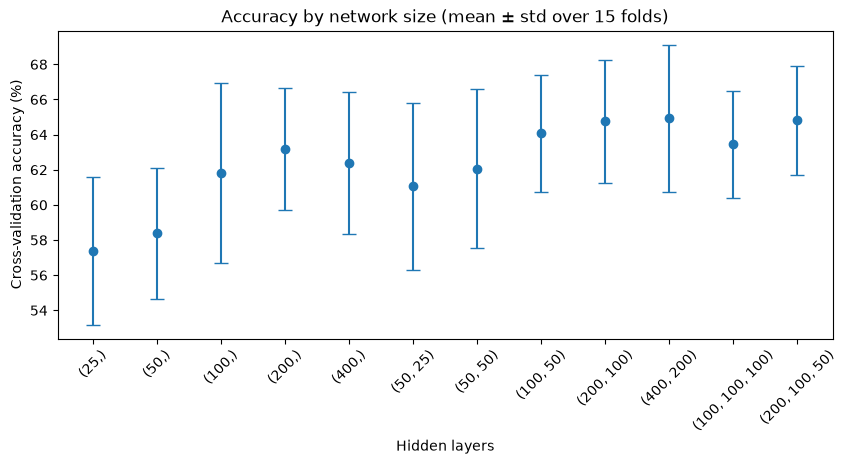

In [11]:
plt.figure(figsize=(10, 4))
plt.errorbar(layer_df["layers"], layer_df["mean_accuracy"] * 100,
             yerr=layer_df["std"] * 100, marker="o", linestyle="none", capsize=5)
plt.xticks(rotation=45)
plt.xlabel("Hidden layers")
plt.ylabel("Cross-validation accuracy (%)")
plt.title("Accuracy by network size (mean ± std over 15 folds)")
plt.show()

In [12]:
final_layers = (100, 50)

best_settings = dict(hidden_layer_sizes=final_layers, activation=best_activation,
                     solver=best_solver, alpha=best_alpha, max_iter=3000)
best_settings

{'hidden_layer_sizes': (100, 50),
 'activation': 'relu',
 'solver': 'lbfgs',
 'alpha': 0.01,
 'max_iter': 3000}

### 3.3. Input encoding: plain numbers vs one-hot

In [13]:
encoding_results = []

for name, data in [("plain numbers", X), ("one-hot", X_onehot)]:
    # same settings and seed -> the same rows go into training for both encodings
    X_tr, X_te, y_tr, y_te = train_test_split(data, y, test_size=0.2, stratify=y, random_state=0)
    scores = cross_val_score(MLPClassifier(random_state=0, **best_settings),
                             X_tr, y_tr, cv=cv, scoring="accuracy", n_jobs=-1)
    encoding_results.append({"encoding": name, "input_columns": X_tr.shape[1],
                             "mean_accuracy": scores.mean(), "std": scores.std()})

encoding_df = pd.DataFrame(encoding_results)
encoding_df.round(3)

/Users/yasandu/Desktop/taxi-driver/submission/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/Users/yasandu/Desktop/taxi-driver/submission/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check

,encoding,input_columns,mean_accuracy,std
0,plain numbers,4,0.609,0.035
1,one-hot,11,0.641,0.033


## 4. Choosing the train/test split

In [14]:
split_results = []
split_cms = {}                                   # one combined confusion matrix per split

for test_size in [0.4, 0.3, 0.2, 0.1]:
    scores = []
    total_cm = np.zeros((6, 6), dtype=int)       # empty 6x6 matrix for this split

    for split_seed in range(5):                  # 5 different shuffles
        X_tr, X_te, y_tr, y_te = train_test_split(
            X_onehot, y, test_size=test_size, stratify=y, random_state=split_seed)

        split_model = MLPClassifier(random_state=0, **best_settings)
        split_model.fit(X_tr, y_tr)
        y_pred = split_model.predict(X_te)

        scores.append(accuracy_score(y_te, y_pred))
        total_cm += confusion_matrix(y_te, y_pred, labels=range(6))   # add this run's matrix

    split_name = f"{round((1 - test_size) * 100)}/{round(test_size * 100)}"
    split_cms[split_name] = total_cm
    split_results.append({
        "split": split_name,
        "train_rows": len(X_tr),
        "test_rows": len(X_te),
        "mean_accuracy": np.mean(scores),
        "std": np.std(scores),
        "lowest": min(scores),
        "highest": max(scores),
    })

split_df = pd.DataFrame(split_results)
split_df.round(3)

/Users/yasandu/Desktop/taxi-driver/submission/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/Users/yasandu/Desktop/taxi-driver/submission/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check

,split,train_rows,test_rows,mean_accuracy,std,lowest,highest
0,60/40,240,160,0.681,0.038,0.638,0.750
1,70/30,280,120,0.718,0.037,0.683,0.775
2,80/20,320,80,0.745,0.055,0.675,0.812
3,90/10,360,40,0.750,0.047,0.675,0.800


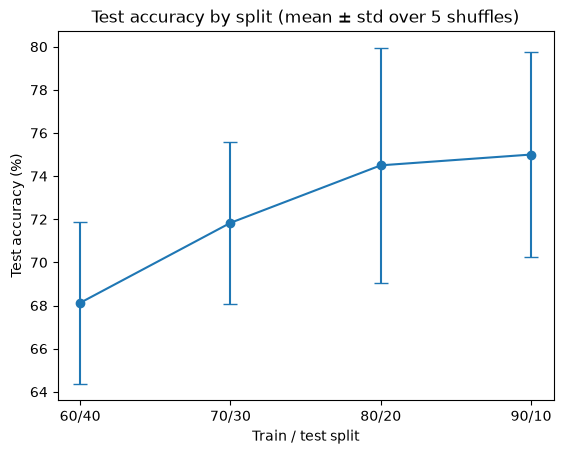

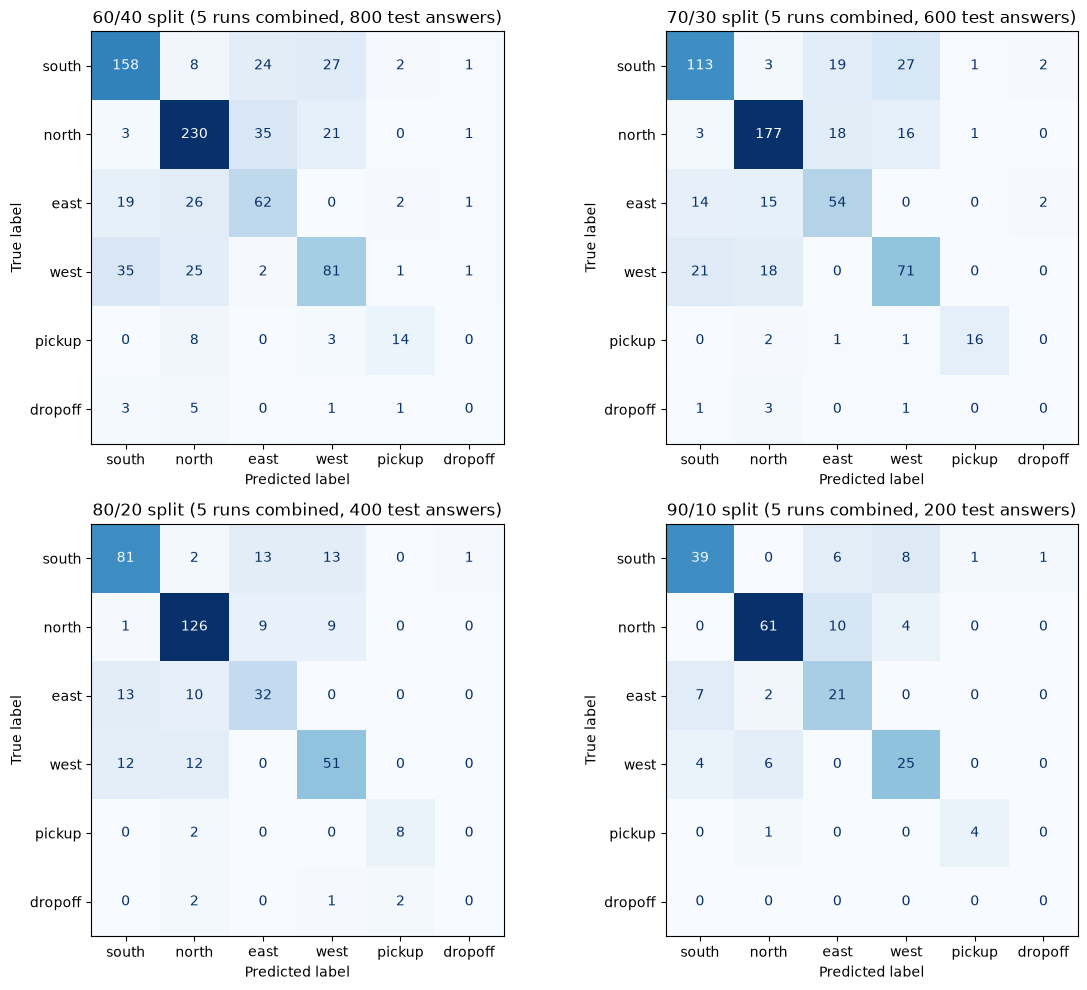

In [15]:
# chart 1: accuracy by split
plt.errorbar(split_df["split"], split_df["mean_accuracy"] * 100,
             yerr=split_df["std"] * 100, marker="o", capsize=5)
plt.xlabel("Train / test split")
plt.ylabel("Test accuracy (%)")
plt.title("Test accuracy by split (mean ± std over 5 shuffles)")
plt.show()

# chart 2: confusion matrix for each split (5 runs added together)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (split_name, cm) in zip(axes.flat, split_cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=action_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{split_name} split (5 runs combined, {cm.sum()} test answers)")
plt.tight_layout()
plt.show()

## 5. Final network

In [16]:
# rerun the main split here so nothing earlier can have overwritten it
X_train, X_test, y_train, y_test = train_test_split(
    X_onehot, y, test_size=0.2, stratify=y, random_state=0)

final_model = MLPClassifier(random_state=0, **best_settings)
final_model.fit(X_train, y_train)

# one function that measures the network on any part of the data
def evaluate(model, X_part, y_part, part_name):
    y_pred = model.predict(X_part)
    y_prob = model.predict_proba(X_part)
    y_true_onehot = np.eye(6)[y_part]

    print(f"===== {part_name} ({len(y_part)} rows) =====")
    print("Accuracy:", round(accuracy_score(y_part, y_pred), 3))
    print("ROC-AUC (macro, one-vs-rest):",
          round(roc_auc_score(y_part, y_prob, multi_class="ovr", average="macro"), 3))
    print("RMSE (probabilities):", round(np.sqrt(mean_squared_error(y_true_onehot, y_prob)), 3))
    print("RMSE (action numbers):", round(np.sqrt(mean_squared_error(y_part, y_pred)), 3))
    print(classification_report(y_part, y_pred, labels=range(6),
                                target_names=action_names, zero_division=0))
    return confusion_matrix(y_part, y_pred, labels=range(6))

# measure it on both sets, as the brief asks
train_cm = evaluate(final_model, X_train, y_train, "TRAINING data")
test_cm = evaluate(final_model, X_test, y_test, "TEST (unseen) data")

===== TRAINING data (320 rows) =====
Accuracy: 1.0
ROC-AUC (macro, one-vs-rest): 1.0
RMSE (probabilities): 0.0
RMSE (action numbers): 0.0
              precision    recall  f1-score   support

       south       1.00      1.00      1.00        88
       north       1.00      1.00      1.00       116
        east       1.00      1.00      1.00        45
        west       1.00      1.00      1.00        58
      pickup       1.00      1.00      1.00        10
     dropoff       1.00      1.00      1.00         3

    accuracy                           1.00       320
   macro avg       1.00      1.00      1.00       320
weighted avg       1.00      1.00      1.00       320

===== TEST (unseen) data (80 rows) =====
Accuracy: 0.762
ROC-AUC (macro, one-vs-rest): 0.926
RMSE (probabilities): 0.26
RMSE (action numbers): 1.157
              precision    recall  f1-score   support

       south       0.71      0.68      0.70        22
       north       0.88      0.97      0.92        29
       

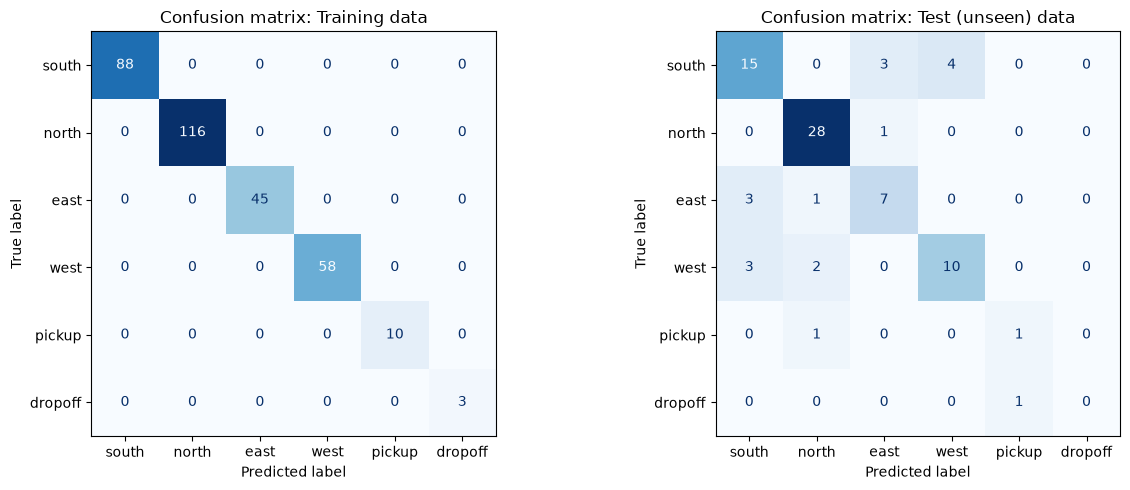

In [17]:
# both confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cm, title in zip(axes, [train_cm, test_cm], ["Training data", "Test (unseen) data"]):
    ConfusionMatrixDisplay(cm, display_labels=action_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix: {title}")
plt.tight_layout()
plt.show()

## 6. Memorisation check: shuffled labels

In [18]:
rng = np.random.default_rng(0)
y_train_shuffled = pd.Series(rng.permutation(y_train.values), index=y_train.index)

shuffled_model = MLPClassifier(random_state=0, **best_settings)
shuffled_model.fit(X_train, y_train_shuffled)

memorisation_df = pd.DataFrame([
    {"labels": "real",
     "training accuracy": accuracy_score(y_train, final_model.predict(X_train)),
     "test accuracy": accuracy_score(y_test, final_model.predict(X_test))},
    {"labels": "shuffled (no pattern)",
     "training accuracy": accuracy_score(y_train_shuffled, shuffled_model.predict(X_train)),
     "test accuracy": accuracy_score(y_test, shuffled_model.predict(X_test))},
])
print("Always guessing the most common action would score:",
      round((y_test == y_train.mode()[0]).mean(), 3), "on the test set")
memorisation_df.round(3)

Always guessing the most common action would score: 0.362 on the test set


/Users/yasandu/Desktop/taxi-driver/submission/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


,labels,training accuracy,test accuracy
0,real,1.0,0.762
1,shuffled (no pattern),1.0,0.275


## 7. Control: the network drives the taxi

In [19]:
env = gym.make("Taxi-v4")
u = env.unwrapped

# the two controllers: each looks at the current state and returns an action 
def network_controller(state):
    # X_onehot already holds the 11 input columns for every reachable state, indexed by state number
    return int(final_model.predict(X_onehot.loc[[state]])[0])

def q_table_controller(state):
    return int(full_dataset_df.loc[state, "best_action"])    # the Q-learning optimum action

# drive one trip with a controller, from a chosen start state
def drive(controller, start_state, max_steps=200):
    env.reset()
    u.s = start_state                  # force this start configuration
    state = start_state
    total_reward = 0
    illegal_moves = 0

    for step in range(1, max_steps + 1):
        action = controller(state)
        state, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        if reward == -10:              # illegal pickup or drop-off
            illegal_moves += 1
        if terminated:                 # passenger delivered
            return {"delivered": True, "steps": step, "reward": total_reward, "illegal": illegal_moves}

    return {"delivered": False, "steps": max_steps, "reward": total_reward, "illegal": illegal_moves}

# all 300 starting configurations 
start_states = []
for s in range(500):
    taxi_row, taxi_col, pass_idx, dest_idx = u.decode(s)
    if pass_idx < 4 and pass_idx != dest_idx:
        start_states.append(s)
print("Start states:", len(start_states))

rows = []
for s in start_states:
    q = drive(q_table_controller, s)
    n = drive(network_controller, s)
    rows.append({"state": s,
                 "q_delivered": q["delivered"], "q_steps": q["steps"], "q_reward": q["reward"],
                 "nn_delivered": n["delivered"], "nn_steps": n["steps"], "nn_reward": n["reward"],
                 "nn_illegal": n["illegal"]})
drive_df = pd.DataFrame(rows).set_index("state")

delivered = drive_df[drive_df["nn_delivered"]]
failed = drive_df[~drive_df["nn_delivered"]]

print("Q-table delivered:", drive_df["q_delivered"].sum(), "/ 300")
print("Network delivered:", drive_df["nn_delivered"].sum(), "/ 300")
print("Delivered trips as short as the Q-table's:", (delivered["nn_steps"] == delivered["q_steps"]).sum(),
      "/", len(delivered))
print("Average reward  Q-table:", round(drive_df["q_reward"].mean(), 2),
      "| Network:", round(drive_df["nn_reward"].mean(), 2))
print("Failed trips stuck repeating an illegal pickup/drop-off:", (failed["nn_illegal"] > 0).sum())
print("Failed trips stuck moving back and forth:", (failed["nn_illegal"] == 0).sum())

Start states: 300
Q-table delivered: 300 / 300
Network delivered: 175 / 300
Delivered trips as short as the Q-table's: 174 / 175
Average reward  Q-table: 7.93 | Network: -480.15
Failed trips stuck repeating an illegal pickup/drop-off: 71
Failed trips stuck moving back and forth: 54
